# RAG

Implement RAG with reranking, chunking and vectorDB

In [1]:
!pip install -U pinecone sentence-transformers transformers datasets plotly nbformat kaleido

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [kaleido]


### 1. Load and Inspect the data

Inspect and understand the data before performing any operations.

#### Load the dataset

In [4]:
from datasets import load_dataset

ds = load_dataset("allenai/sciq")
ds.set_format("pandas")
df = ds["train"][:]
df.head()

/opt/anaconda3/envs/tf/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,question,distractor3,distractor1,distractor2,correct_answer,support
0,What type of organism is commonly used in prep...,viruses,protozoa,gymnosperms,mesophilic organisms,"Mesophiles grow best in moderate temperature, ..."
1,What phenomenon makes global winds blow northe...,tropical effect,muon effect,centrifugal effect,coriolis effect,Without Coriolis Effect the global winds would...
2,Changes from a less-ordered state to a more-or...,endothermic,unbalanced,reactive,exothermic,Summary Changes of state are examples of phase...
3,What is the least dangerous radioactive decay?,zeta decay,beta decay,gamma decay,alpha decay,All radioactive decay is dangerous to living t...
4,Kilauea in hawaii is the world’s most continuo...,magma,greenhouse gases,carbon and smog,smoke and ash,Example 3.5 Calculating Projectile Motion: Hot...


#### Analyse the dataset

In [5]:
supports = df['support'].dropna().unique().tolist()
support_lengths = [len(s) for s in supports]
print(f"Total unique support documents: {len(supports)}")
print("Sample article")
print(supports[:1])

Total unique support documents: 10474
Sample article
['Mesophiles grow best in moderate temperature, typically between 25°C and 40°C (77°F and 104°F). Mesophiles are often found living in or on the bodies of humans or other animals. The optimal growth temperature of many pathogenic mesophiles is 37°C (98°F), the normal human body temperature. Mesophilic organisms have important uses in food preparation, including cheese, yogurt, beer and wine.']


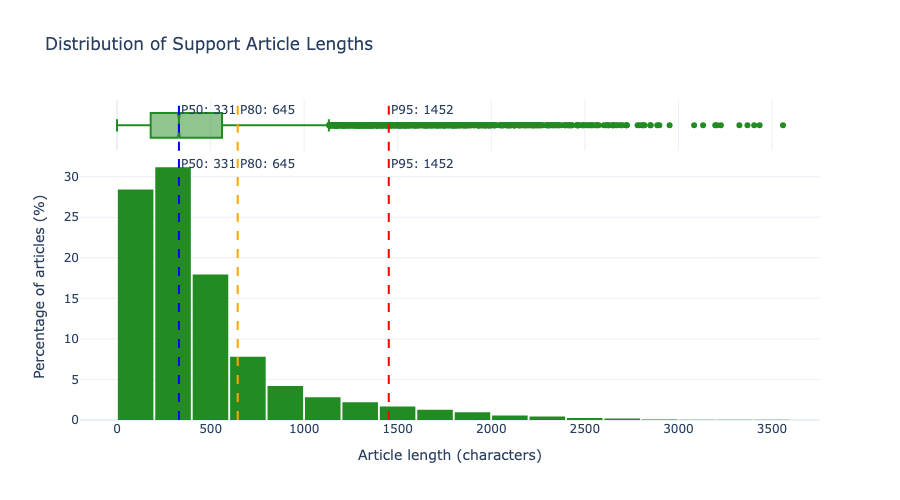

count    10474.0
mean       465.0
std        448.0
min          0.0
10%         89.0
25%        180.0
50%        331.0
75%        561.0
80%        645.0
90%       1026.0
95%       1452.0
99%       2209.0
max       3559.0
Name: length, dtype: float64


In [6]:
import numpy as np
import pandas as pd
import plotly.express as px

lengths_df = pd.DataFrame({"length": support_lengths})

# Histogram of article lengths with a box plot on top
fig = px.histogram(
    lengths_df,
    x="length",
    nbins=20,
    histnorm="percent",
    marginal="box",
    title="Distribution of Support Article Lengths",
    labels={"length": "Article length (characters)"},
    color_discrete_sequence=["forestgreen"],
)

# Mark key percentiles
for p, color in [(50, "blue"), (80, "orange"), (95, "red")]:
    v = np.percentile(support_lengths, p)
    fig.add_vline(x=v, line_dash="dash", line_color=color,
                  annotation_text=f"P{p}: {int(v)}", annotation_position="top right")
fig.update_layout(template="plotly_white", yaxis_title="Percentage of articles (%)", bargap=0.05)

# Render as static PNG so the chart shows on GitHub (interactive plotly needs JavaScript, which GitHub doesn't run)
fig.show(renderer="png", width=900, height=500)

print(lengths_df["length"].describe(percentiles=[.1, .25, .5, .75, .8, .9, .95, .99]).round(0))


#### Analysis of Article Lengths

**Dataset:** 10,474 unique support articles (character counts).

| Statistic | Characters | ≈ Words |
|---|---|---|
| Min | 0 (some empty articles) | 0 |
| Median (P50) | 331 | ~50 |
| Mean | 465 | ~70 |
| P75 | 561 | ~85 |
| P80 | 645 | ~100 |
| P90 | 1,026 | ~155 |
| P95 | 1,452 | ~220 |
| Max | 3,559 | ~540 |

**Shape:** Right-skewed, not a bell curve. Most articles are short, with a long tail of a few very long ones. The mean (465) is higher than the median (331) because of that tail.

#### How much needs chunking?

The embedding model `all-MiniLM-L6-v2` only reads the first **256 tokens** (≈ 190 words ≈ **1,000 characters**) and ignores the rest.

| Length range | Share of articles | Needs chunking? |
|---|---|---|
| < 645 chars | ~80% | No |
| 645 – 1,026 chars | ~10% | No (fits within 256 tokens) |
| > 1,026 chars | **~10%** | **Yes**, otherwise the end of the article is never embedded |

**Takeaways:**
- Only about **10%** of articles (~1,000 docs) need chunking.
- Use `chunk_size ≈ 800–1,000` chars with `overlap ≈ 100–150`, so short articles stay whole and only the long ones are split.
- Filter out empty articles (length 0) before embedding.
- Rough conversion: 1 token ≈ ¾ word ≈ 4 characters.


### 2. Store data in DB

#### 1. Create a Pinecone DB

In [36]:
import torch
from pinecone import Pinecone, ServerlessSpec
import os

PINECONE_API_KEY = os.environ['PINECONE_API_KEY']

device = "mps" if torch.backends.mps.is_available() else "cpu"
print(f"Using device: {device}")

pc = Pinecone(api_key=PINECONE_API_KEY)

# Create Pinecone index
index_name = "sciq-rag-chunk"

if index_name not in [info["name"] for info in pc.list_indexes()]:
    pc.create_index(
        name=index_name,
        dimension=384,
        metric="cosine",
        spec=ServerlessSpec(cloud="aws", region="us-east-1")
    )

print(pc.list_indexes())

# Connect to Pinecone Index
index = pc.Index(index_name)


Using device: mps
IndexList([<name='sciq-rag-chunk', ready=True>])


#### 2. Embedding and Chunking

In [50]:
import unicodedata
from sentence_transformers import SentenceTransformer

# 1. Initialize embedding model
embedder = SentenceTransformer("all-MiniLM-L6-v2", device=device)

# 2. Define chunking strategy
def chunk_text(text, chunk_size=100, overlap=15):
    if len(text) <= chunk_size:
      return [text]

    chunks = []
    start = 0
    while start < len(text):
        chunks.append(text[start : start + chunk_size])
        start += chunk_size - overlap
    return chunks

# 3. Define a function to safely normalize chunks
def safe_chunk(chunk):
    return unicodedata.normalize('NFKD', chunk).encode('ascii', 'ignore').decode('utf-8', 'ignore')

# 4. Define a function to get embeddings for chunks
def get_embeddings(chunks):
    return embedder.encode(chunks, convert_to_tensor=True, show_progress_bar=False)
   
import textwrap

SAMPLE_SUPPORT_IDX = 200
sample_text = supports[SAMPLE_SUPPORT_IDX]
sample_chunk = chunk_text(sample_text)
embeddings = get_embeddings(sample_chunk)

print("=== Sample article ===")
print(textwrap.fill(sample_text, width=100))
print(f"\nArticle length: {len(sample_text)} chars | Number of chunks: {len(sample_chunk)}\n")

for n, c in enumerate(sample_chunk, 1):
    print(f"--- Chunk {n} ({len(c)} chars) ---")
    print(textwrap.fill(c, width=100))
    print(f"--- Safe Chunk {n} ({len(c)} chars) ---")
    print(textwrap.fill(safe_chunk(c), width=100))
    print(f"Embedding shape for chunk {n}: {embeddings[n-1].shape}")
    print()
    

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5719.38it/s]


=== Sample article ===
When using measuring devices, we often use a technique called calibration to increase the accuracy
of our measurements. Calibration is a method of setting or correcting a measuring device by matching
it to known measurement standards. To better understand calibration, we will look at the example of
calibrating a thermometer. All thermometers are slightly different in their temperature readings.
One way to calibrate a thermometer is by using the freezing point and boiling point of water (
Figure below ). If we know that water freezes at 0°C and boils at 100°C, we can calibrate our
thermometer by measuring the temperature of ice water and of boiling water. We place the thermometer
in ice water and wait for the thermometer liquid to reach a stable height, then place a mark at this
height which represents 0°C. Then we place the thermometer in boiling water, and after waiting for
the thermometer liquid to reach a stable height, we place a mark at this height which rep

Notes : the article was divied into 3 chunks, safe chunk remoed the degree symbol

#### 3. Load the data into VectorDB

Push the embeddings of chunks into the vector DB


In [59]:
# Set to True for dry run (skip actual upsert to Pinecone)
DRY_RUN = False  
if DRY_RUN:
    START_DOCUMENT_IDX = 200
    MAX_DOCUMENTS = 1

from tqdm.auto import tqdm
import time

print("\nUpload embeddings of SciQ support documents (chunks) to Pinecone...")
START_DOCUMENT_IDX = 0
MAX_DOCUMENTS = len(supports)  # Set to the total number of support documents
if len(supports) < MAX_DOCUMENTS:
    MAX_DOCUMENTS = len(supports)
delay_seconds = 0.2

CHUNK_SIZE = 800
CHUNK_OVERLAP = 150

print(f"Processing {MAX_DOCUMENTS} support documents with a delay of {delay_seconds} seconds between upserts.")

for i in tqdm(range(START_DOCUMENT_IDX, START_DOCUMENT_IDX+MAX_DOCUMENTS)):

    if not DRY_RUN:
        # check if a document has already been processed by checking if the first chunk exists in the index
        first_chunk_id = f"doc-{i}-chunk-0"
        if index.fetch(ids=[first_chunk_id])['vectors']:
            continue

    if DRY_RUN:
        print(f"\nProcessing document {i} of {len(supports)}...")
        print(supports[i][:100])  # Print the first 100 characters of the support document for reference
    
    # 1. Chunk the support document
    chunks = chunk_text(supports[i], chunk_size=CHUNK_SIZE, overlap=CHUNK_OVERLAP)

    # 2. Generate embeddings for all chunks
    embeddings = get_embeddings(chunks)

    # 3. Prepare data for upsert to Pinecone
    upsert_data = []
    title = supports[i][:50]  # Store the first 50 characters of the support document as title

    for j, chunk in enumerate(chunks):
        clean_text = safe_chunk(chunk)
        embedding = embeddings[j].cpu().numpy().tolist()
        doc_id = f"doc-{i}-chunk-{j}"

        upsert_data.append({
            "id": doc_id,
            "values": embedding,
            "metadata": {
                "title": title, 
                "text": clean_text
            }
        })

    if DRY_RUN:
        print(f"Prepared upsert data for document {i} with {len(chunks)} chunks.")
        print(f"Upsert data length: {len(upsert_data)}")
        print(f"First chunk ID: {upsert_data[0]['id']}, Title: {title}, Text: {upsert_data[0]['metadata']['text'][:50]}...")

    # Upsert batch to Pinecone
    if not DRY_RUN:
        index.upsert(vectors=upsert_data)

    if delay_seconds > 0:
        time.sleep(delay_seconds)

print("\nSuccessfully uploaded SciQ support document embeddings to Pinecone.")


Upload embeddings of SciQ support documents (chunks) to Pinecone...
Processing 10474 support documents with a delay of 0.2 seconds between upserts.


100%|██████████| 10474/10474 [2:56:17<00:00,  1.01s/it]    


Successfully uploaded SciQ support document embeddings to Pinecone.


#### 4. Quick Test

In [78]:
# Quick test query on the newly populated SciQ index
query_text = "What is the technique used to increase the accuracy of measuring devices?"
query_vector = embedder.encode(query_text, convert_to_numpy=True).tolist()
results = index.query(vector=query_vector, top_k=5, include_metadata=True)

for match in results['matches'][0:5]:
    print(f"\nScore: {match['score']:.4f}")
    print(f"Match ID: {match['id']}")
    print(f"Title: {match['metadata']['title']}")
    print(f"Text: {match['metadata']['text'][:200]}...")  # Print first 200 characters of the text


Score: 0.6761
Match ID: doc-772-chunk-0
Title: Accuracy means making measurements that are close 
Text: Accuracy means making measurements that are close to the true value....

Score: 0.5984
Match ID: doc-2240-chunk-0
Title: Measurement is the process of making an observatio
Text: Measurement is the process of making an observation in terms of a numerical scale and recording the value....

Score: 0.5842
Match ID: doc-200-chunk-0
Title: When using measuring devices, we often use a techn
Text: When using measuring devices, we often use a technique called calibration to increase the accuracy of our measurements. Calibration is a method of setting or correcting a measuring device by matching ...

Score: 0.5790
Match ID: doc-3009-chunk-1
Title: Accuracy and Precision of a Measurement Science is
Text: your measurement would not be very accurate. The precision of a measurement system is refers to how close the agreement is between repeated measurements (which are repeated under the same cond

### 3. Generate   

In [122]:
from sentence_transformers import CrossEncoder

# Load the reranker model with device specification
reranker_model = CrossEncoder('cross-encoder/ms-marco-TinyBERT-L-2', device=device)

Loading weights: 100%|██████████| 41/41 [00:00<00:00, 11520.50it/s]


In [127]:
DRY_RUN = True  # Set to True for dry run

def get_ranked_results(query_text, top_embeddings_count=10, top_rerank_count=5):

    if DRY_RUN:
        print(f"\nDry run: Preparing to query LLM with query: '{query_text}'")
        print(f"Top embeddings count: {top_embeddings_count}, Top rerank count: {top_rerank_count}")

    # 1. Get the embedding for the query
    query_vector = get_embeddings(query_text).cpu().numpy().tolist()

    # 2. Query Pinecone for top-k matches
    results = index.query(vector=query_vector, top_k=top_embeddings_count, include_metadata=True)
    if DRY_RUN:
        print(f"\nEmbedding results:")
        for i, match in enumerate(results['matches']):
            print(f"{match['score']:.4f} | Title: '{match['metadata']['title'][:15]}', Text: '{match['metadata']['text'][:50]}...'")

    # 3. Prepare pairs for reranking
    pairs = [(query_text, match['metadata']['text']) for match in results['matches']]

    # 4. Rerank using the CrossEncoder model
    rerank_scores = reranker_model.predict(pairs)

    # 5. Combine results with scores and sort
    ranked_results = sorted(zip(results['matches'], rerank_scores), key=lambda x: x[1], reverse=True)
    if DRY_RUN:
        print(f"\nReranked results:")
        for match, score in ranked_results:
            print(f"{score:.4f} | Title: '{match['metadata']['title'][:15]}', Text: '{match['metadata']['text'][:50]}...'")

    return ranked_results[:top_rerank_count]

ranked_results = get_ranked_results("What is the technique used to increase the accuracy of measuring devices?", top_embeddings_count=5, top_rerank_count=5)


Dry run: Preparing to query LLM with query: 'What is the technique used to increase the accuracy of measuring devices?'
Top embeddings count: 5, Top rerank count: 5

Embedding results:
0.6761 | Title: 'Accuracy means ', Text: 'Accuracy means making measurements that are close ...'
0.5984 | Title: 'Measurement is ', Text: 'Measurement is the process of making an observatio...'
0.5842 | Title: 'When using meas', Text: 'When using measuring devices, we often use a techn...'
0.5790 | Title: 'Accuracy and Pr', Text: 'your measurement would not be very accurate. The p...'
0.5745 | Title: 'precision: A me', Text: 'precision: A measure of how close a series of meas...'

Reranked results:
0.9744 | Title: 'When using meas', Text: 'When using measuring devices, we often use a techn...'
0.3293 | Title: 'Accuracy and Pr', Text: 'your measurement would not be very accurate. The p...'
0.2965 | Title: 'Accuracy means ', Text: 'Accuracy means making measurements that are close ...'
0.2689 | Title: 'Me

#### Analysis of Reranking

Reranking moved our correct passage (the one about **calibration**) from **3rd → 1st**.

| Passage | Embedding score (rank) | Rerank score (rank) |
|---|---|---|
| "When using measuring devices… **calibration**…" | 0.584 (3) | **0.974 (1)** |
| "your measurement would not be very accurate…" | 0.579 (4) | 0.329 (2) |
| "Accuracy means making measurements…" | 0.676 (1) | 0.297 (3) |
| "Measurement is the process…" | 0.598 (2) | 0.269 (4) |
| "precision: A measure of…" | 0.574 (5) | 0.109 (5) |

**Observations:**
- **Embedding scores are bunched together** (0.57–0.68). Each score is computed independently (cosine similarity of the query vector and one passage vector). The texts returned by embedding model are close to eachother since they are all around the same topic. These 5 are all "about measurement/accuracy". The bi-encoder compares *embeddings*, not the actual *text*: the query and each passage are first compressed into vectors, and only those vectors are compared. This captures topic similarity, but not whether the passage actually *answers* the question.
- **Rerank scores are well separated** (0.97 vs ≤ 0.33). The cross-encoder reads the query and passage *together*, so it recognizes that only the calibration passage contains the answer ("a technique called calibration to increase the accuracy").
- The embedding's top hit ("Accuracy means…") is a short definition that shares keywords with the query but doesn't answer it. Reranking pushed it down to 3rd.

**Limitation:** The reranker only reorders the `top_k` candidates returned by Pinecone, so the *set* of passages stays the same. If the correct passage isn't in the initial retrieval, reranking can't recover it. A common fix is to retrieve more candidates (e.g. 20–50), rerank them all, and keep the top 5.

**Takeaway:** Retrieval (bi-encoder) is fast and gives good *recall*; reranking (cross-encoder) is slower but gives better *precision*. Combining them puts the best context first for the LLM.

In [167]:
from google import genai

DRY_RUN = True  # Set to True for dry run (skip LLM api calls)
def askLLM(query, prompt_template=None):
    reranked_results = get_ranked_results(query, top_embeddings_count=10, top_rerank_count=5)

    context = "\n\n".join(match['metadata']['text'] for match, _ in reranked_results)

    if prompt_template:
        prompt = prompt_template.format(query=query, context=context)
    else:
        prompt = f'''You are a question-answering system who answers **ONLY** based on the context provided to you.
                Answer in a **consise** manner
                If the context does not contain the answer to my question, respond "I don't have enough data to answer your question".
                **NEVER** invent or use information outside of the context provided.
                Respond in less than 50 words.

                QUESTION: {query}
                CONTEXT:
                {context}'''
    if DRY_RUN:
        print(f"\nDry run: Prepared prompt for LLM:\n\n{prompt}")
        return "This is a dry run. No actual LLM call was made."

    client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])
    response = client.models.generate_content(
        model="gemini-2.5-flash",
        contents=prompt
    )
    return response.text

answer = askLLM(query_text)


Dry run: Preparing to query LLM with query: 'What is the technique used to increase the accuracy of measuring devices?'
Top embeddings count: 10, Top rerank count: 5

Embedding results:
0.6761 | Title: 'Accuracy means ', Text: 'Accuracy means making measurements that are close ...'
0.5984 | Title: 'Measurement is ', Text: 'Measurement is the process of making an observatio...'
0.5842 | Title: 'When using meas', Text: 'When using measuring devices, we often use a techn...'
0.5790 | Title: 'Accuracy and Pr', Text: 'your measurement would not be very accurate. The p...'
0.5745 | Title: 'precision: A me', Text: 'precision: A measure of how close a series of meas...'
0.5695 | Title: 'Accuracy and Pr', Text: 'Accuracy and Precision of a Measurement Science is...'
0.5602 | Title: 'Scientists make', Text: 'Scientists make many measurements during experimen...'
0.5519 | Title: 'A thermometer i', Text: 'A thermometer is a device used to measure temperat...'
0.5439 | Title: 'Measuring devic', Te

In [168]:
DRY_RUN = False # Set to False to enable actual LLM API calls
answer = askLLM(query_text)
print(f"\nRAG based LLM Response:\n{answer}")


RAG based LLM Response:
The technique used to increase the accuracy of measuring devices is called calibration.


### 4. Evals

#### Why evaluate?

For the test question, the LLM gave a correct but wordy answer:

| Source | Answer |
|---|---|
| LLM | "The technique used to increase the accuracy of measuring devices is called calibration." |
| Dataset (`correct_answer`) | "calibration" |

The answer is right, but an exact-match comparison would mark it **wrong**. To evaluate fairly we need to:
1. **Inspect the dataset:** check the question and answer lengths (answers are at most 12 words, usually 1–3).
2. **Tighten the prompt:** ask for only the short answer phrase, not a full sentence.
3. **Compare robustly:** normalize case and punctuation, or check whether the expected answer appears in the LLM's answer.

**Running at scale:** evaluating thousands of questions on a hosted free tier (Gemini, Groq) quickly hits per-minute and per-day limits. Use a **local model (Ollama)** instead: it's free and has no rate limits.


#### 1. Analyse Test Data

In [165]:
questions = df['question'].tolist()
answers = df['correct_answer'].tolist()

print(f"Total questions: {len(questions)}")
print(f"Total answers: {len(answers)}")

# max length of questions and answers
max_question_length = max(len(q.split()) for q in questions)
max_answer_length = max(len(a.split()) for a in answers)
print(f"Max question words: {max_question_length} words")
print(f"Max answer words: {max_answer_length} words")

Total questions: 11679
Total answers: 11679
Max question words: 68 words
Max answer words: 12 words


In [162]:
for i in range(200,250):
    if "measur" in questions[i]:
        print(f"{i} Quest: {questions[i]}") 

answers[226]

214 Quest: What is a mass spectrometer used to measure?
226 Quest: What is the method of setting or correcting a measuring device by matching it to known measurement standards called?
229 Quest: What unit of measure is equal to the amount of work a horse can do in 1 minute?
241 Quest: To measure what changes that occur in chemical reactions, chemists usually use a related thermodynamic quantity, calledenthalpy?


'calibration'

#### 2. Harden the prompt

In [172]:
prompt = '''You are a question-answering system. Answer the question **ONLY** using the provided context.

Answer format rules:
- Output ONLY the answer itself: a short phrase, name, number, or term.
- Do NOT write a full sentence. Do NOT restate the question.
- Use the shortest span that fully answers the question (usually 1-5 words, never more than 12 words).
- Prefer wording copied exactly from the context.
- No explanation, no preamble, no trailing period.

Examples:
Question: What process do plants use to convert sunlight into chemical energy?
Answer: photosynthesis

Question: What is the SI unit of force?
Answer: newton

If the context does not contain the answer, respond exactly: I don't have enough data to answer your question
**NEVER** invent or use information outside of the context.

Question: {query}

Context:
{context}

Answer:'''

In [173]:
answer = askLLM(query=query_text, prompt_template=prompt)
print(f"LLM answer:      {answer}")
print(f"Expected answer: {answers[226]}")

LLM answer:      calibration
Expected answer: calibration


#### Harden the prompt with few-shot prompting

Instructions alone ("be concise") still let the LLM answer in full sentences. **Few-shot prompting** adds a few example question → answer pairs to the prompt, so the model copies the *format* we want.

| Technique | What the prompt contains | Typical output |
|---|---|---|
| Zero-shot | Instructions only | "The technique ... is called calibration." |
| Few-shot | Instructions + 2–3 examples | "calibration" |

**Guidelines for good examples:**
- **Match the target format:** short answers (1–3 words), lowercase, no trailing period, the same style as the dataset's `correct_answer`.
- **Avoid leaking test answers:** use examples that aren't the question being evaluated.
- **Cover edge cases:** include one example where the context lacks the answer, so the model learns the fallback response.
- **Keep it small:** 2–5 examples is enough. More examples add tokens to every call (cost and rate limits).


#### 2. Use Local LLM Ollama

In [174]:
# Local LLM via Ollama (free, no rate limits)
# Prerequisites (run in a terminal, NOT here):
#   brew install ollama
#   brew services start ollama      # or: ollama serve (in its own terminal)
#   ollama pull qwen2.5:7b
%pip install -q ollama

import ollama

OLLAMA_MODEL = "qwen2.5:7b"

def askLocalLLM(query, prompt_template):
    reranked_results = get_ranked_results(query, top_embeddings_count=10, top_rerank_count=5)
    context = "\n\n".join(match['metadata']['text'] for match, _ in reranked_results)
    prompt = prompt_template.format(query=query, context=context)

    response = ollama.chat(
        model=OLLAMA_MODEL,
        messages=[{"role": "user", 
                    "content": prompt}],
        options={"temperature": 0,        # same answer every run, short output
                 "num_predict": 30},      # limit output to 30 tokens (~20 words)
    )
    return response["message"]["content"].strip()

DRY_RUN = False
answer = askLocalLLM(query_text, prompt_template=prompt)
print(f"LLM answer:      {answer}")
print(f"Expected answer: {answers[226]}")

Note: you may need to restart the kernel to use updated packages.
LLM answer:      calibration
Expected answer: calibration


#### 3. Evaluate all questions with the local LLM

In [182]:
# Run this script in a terminal to keep the Mac awake while it runs (otherwise it may sleep and interrupt the process):
# caffeinate -dims

import json

# Resumable: answers are saved to disk, so re-running skips questions already answered
CACHE_FILE = os.path.join(os.environ.get("OUTPUT_DIR", ""), "llm_answers.json")
cache = json.load(open(CACHE_FILE)) if os.path.exists(CACHE_FILE) else {}

for i in tqdm(range(len(questions)), initial=0):
    if str(i) in cache:
        continue
    cache[str(i)] = askLocalLLM(query=questions[i], prompt_template=prompt)
    if i % 20 == 0:
        json.dump(cache, open(CACHE_FILE, "w"))
json.dump(cache, open(CACHE_FILE, "w"))


  5%|▍         | 569/11679 [54:36<17:46:19,  5.76s/it]


KeyboardInterrupt: 

In [193]:
# Score
wrong_answers = [(int(i), a, answers[int(i)]) for i, a in cache.items()
                 if a.strip().lower() != answers[int(i)].strip().lower()]
total = len(cache)
print(f"\nTotal wrong answers: {len(wrong_answers)} out of {total} questions.")
print(f"Accuracy: {(total - len(wrong_answers)) / total * 100:.2f}%")
print("\nWrong answers:")
for i, LLM_answer, correct_answer in wrong_answers[:50]:
    print(f"Q: {i}: LLM answer: {LLM_answer} | Correct answer: {correct_answer}")


Total wrong answers: 252 out of 569 questions.
Accuracy: 55.71%

Wrong answers:
Q: 0: LLM answer: bacteria | Correct answer: mesophilic organisms
Q: 2: LLM answer: reversed | Correct answer: exothermic
Q: 4: LLM answer: I don't have enough data to answer your question | Correct answer: smoke and ash
Q: 8: LLM answer: type of radioactivity | Correct answer: radioactivity
Q: 10: LLM answer: active | Correct answer: active metal
Q: 11: LLM answer: genes and experiences | Correct answer: animal behaviors
Q: 14: LLM answer: regulatory proteins | Correct answer: gene transcription
Q: 16: LLM answer: circulatory systems | Correct answer: circulatory
Q: 17: LLM answer: Allergies | Correct answer: allergy
Q: 18: LLM answer: zygote | Correct answer: a zygote
Q: 19: LLM answer: allows for both asexual and sexual reproduction | Correct answer: reproduce asexually and sexually
Q: 21: LLM answer: termination | Correct answer: abortion
Q: 24: LLM answer: making observations or performing experiments

In [185]:
FALLBACK = "i don't have enough data"
MAX_PRINT = 50  # max rows to print per group

dont_know_group, wrong_group, correct_group = [], [], []
for k, llm_answer in cache.items():
    i = int(k)
    row = (i, questions[i], llm_answer, answers[i])
    if FALLBACK in llm_answer.lower():
        dont_know_group.append(row)
    elif llm_answer.strip().lower() != answers[i].strip().lower():
        wrong_group.append(row)
    else:
        correct_group.append(row)

total = len(cache)
print(f"Total: {total} | Correct: {len(correct_group)} | "
      f"Don't know: {len(dont_know_group)} | Wrong: {len(wrong_group)}")
print(f"Accuracy: {len(correct_group) / total * 100:.2f}%\n")

def print_group(name, group):
    print(f"\n===== {name} ({len(group)}) =====")
    for i, q, llm_answer, correct in group[:MAX_PRINT]:
        print(f"[{i}] Q: {q}")
        print(f"     LLM answer:     {llm_answer}")
        print(f"     Correct answer: {correct}\n")

print_group("I DON'T KNOW", dont_know_group[:5])
print_group("WRONG ANSWER", wrong_group[:5])

Total: 569 | Correct: 317 | Don't know: 19 | Wrong: 233
Accuracy: 55.71%


===== I DON'T KNOW (5) =====
[4] Q: Kilauea in hawaii is the world’s most continuously active volcano. very active volcanoes characteristically eject red-hot rocks and lava rather than this?
     LLM answer:     I don't have enough data to answer your question
     Correct answer: smoke and ash

[68] Q: What happens to the density of air as the altitude decreases?
     LLM answer:     I don't have enough data to answer your question
     Correct answer: decreases

[71] Q: Dessication is an extreme and usually fatal form of what in animals?
     LLM answer:     I don't have enough data to answer your question
     Correct answer: dehydration

[142] Q: What muscles are used to pump water over the gills?
     LLM answer:     I don't have enough data to answer your question
     Correct answer: jaws and pharynx

[152] Q: What do ranchers fear will happen if wolves return?
     LLM answer:     I don't have enough dat

#### 4. Re-evaluate using LLM (LLM-as-judge)

Exact match is too strict: "Allergies" vs "allergy" or "kinetic energy" vs "kinetic" are marked wrong even though they're correct. So we send each **wrong** answer to the LLM as a "professor" along with the **question, student answer, and correct answer**, and ask for a one-word verdict: `CORRECT` / `INCORRECT`.

In [192]:
# LLM-as-judge: re-check the "wrong" group, since exact match misses
# equivalent answers ("Calibration." vs "calibration", "H2O" vs "water")
JUDGE_PROMPT = '''You are professor grading a student's answer to a science question.
Decide if the student's answer means the same thing as the correct answer.
Ignore case, punctuation, articles (a/an/the), plurals and minor wording differences.
Extra words are fine as long as the core answer matches.
Reply with exactly one word: CORRECT or INCORRECT.

Example:
Question: What type of vertebrates are birds?
LLM answer:     endothermic tetrapod vertebrates
Correct answer: endothermic tetrapod
Verdict: CORRECT

Question: {question}
Student answer: {student}
Correct answer: {correct}

Verdict:'''

JUDGE_CACHE_FILE = os.path.join(os.environ.get("OUTPUT_DIR", ""), "llm_judge.json")
judge_cache = json.load(open(JUDGE_CACHE_FILE)) if os.path.exists(JUDGE_CACHE_FILE) else {}

def judge(question, student, correct):
    response = ollama.chat(
        model=OLLAMA_MODEL,
        messages=[{"role": "user",
                   "content": JUDGE_PROMPT.format(question=question, student=student, correct=correct)}],
        options={"temperature": 0, "num_predict": 5},
    )
    return response["message"]["content"].strip().upper().startswith("CORRECT")

for n, (i, q, llm_answer, correct) in enumerate(tqdm(wrong_group)):
    if str(i) not in judge_cache:
        judge_cache[str(i)] = judge(q, llm_answer, correct)
        if n % 20 == 0:
            json.dump(judge_cache, open(JUDGE_CACHE_FILE, "w"))
json.dump(judge_cache, open(JUDGE_CACHE_FILE, "w"))

judge_correct = [r for r in wrong_group if judge_cache[str(r[0])]]
judge_wrong   = [r for r in wrong_group if not judge_cache[str(r[0])]]

total_correct = len(correct_group) + len(judge_correct)
print(f"Exact-match correct: {len(correct_group)} | Judge rescued: {len(judge_correct)} | "
      f"Still wrong: {len(judge_wrong)} | Don't know: {len(dont_know_group)}")
print(f"Exact-match accuracy: {len(correct_group) / total * 100:.2f}%")
print(f"Judged accuracy:      {total_correct / total * 100:.2f}%")

print_group("JUDGE SAYS CORRECT", judge_correct[:10])
print_group("JUDGE SAYS WRONG", judge_wrong[:10])

100%|██████████| 233/233 [03:39<00:00,  1.06it/s]

Exact-match correct: 317 | Judge rescued: 84 | Still wrong: 149 | Don't know: 19
Exact-match accuracy: 55.71%
Judged accuracy:      70.47%

===== JUDGE SAYS CORRECT (10) =====
[8] Q: Alpha emission is a type of what?
     LLM answer:     type of radioactivity
     Correct answer: radioactivity

[17] Q: What occurs when the immune system attacks a harmless substance that enters the body from the outside?
     LLM answer:     Allergies
     Correct answer: allergy

[18] Q: Fertilization is the union of a sperm and egg, resulting in the formation of what?
     LLM answer:     zygote
     Correct answer: a zygote

[21] Q: What is the termination of a pregnancy in progress called?
     LLM answer:     termination
     Correct answer: abortion

[26] Q: Water molecules move about continuously due to what type of energy?
     LLM answer:     kinetic energy
     Correct answer: kinetic

[32] Q: What type of vertebrates are birds?
     LLM answer:     endothermic tetrapod vertebrates
     Correc

5. Analysis

**Results (570 questions):**

| Category | Count | Share |
|---|---|---|
| Exact-match correct | 317 | 55.6% |
| Rescued by judge | 84 | 14.7% |
| Still wrong | 149 | 26.1% |
| "I don't know" | 19 | 3.3% |
| **Accuracy (exact match)** | | **55.71%** |
| **Accuracy (judged)** | | **70.47%** |

The judge raised accuracy by **~15 points**. Exact match was underestimating the system.

**What the judge rescued (mostly good):**
- Plurals and articles: "Allergies" → allergy, "zygote" → a zygote
- Extra words: "kinetic energy" → kinetic, "divergent plate boundaries" → divergent, "low pressure" → low

**Judge mistakes (be careful):**
- **False positive:** "termination" was accepted for *abortion*. It just repeats a word from the question.
- **False negatives:** "active" vs *active metal* and "circulatory systems" vs *circulatory* were rejected even though they're equivalent. "allows for both asexual and sexual reproduction" also means the same as the correct answer.
- **Grading its own answers:** the same model (`qwen2.5:7b`) answered and graded, so it may be biased. A different or larger judge model is more reliable.

**Why answers are really wrong (looking at "still wrong"):**
1. **Echoing the question:** "making observations or performing experiments", "change in the inherited traits of organisms over time". The model copies text from the question instead of naming the concept (*hypothesis*, *evolution*). A prompt rule ("never repeat words from the question") or a few-shot example could fix this.
2. **Answering the wrong part:** "regulatory proteins" instead of *gene transcription*, "genes and experiences" instead of *animal behaviors*. The model picks the subject of the sentence instead of what was asked.
3. **Retrieval misses:** "bacteria" vs *mesophilic organisms*, "reversed" vs *exothermic*. The right passage probably wasn't in the top 5. Check retrieval recall for these.
4. **Strict gold answers:** some "wrong" answers are reasonable (*bacteria* for cheese/yogurt). The dataset's answers aren't the only valid ones.

**Takeaways:**
- Report **both** numbers. Exact match is the lower bound, and the judged score is closer to the true accuracy.
- Spot-check judge verdicts. Few-shot examples in the judge prompt (like the *endothermic tetrapod* example) help with consistency.
- Next steps: fix question-echoing in the answer prompt, and measure retrieval recall to separate retrieval errors from generation errors.